# EV detection by positive-unlabelled (PU) learning

A real smart-meter population comes with no EV labels, and some households already charge an EV
at home. A classifier deployed on it can therefore be trained only on **known positives** and an
**unlabelled pool** that may hide more of them. This is the positive-unlabelled (PU) setting.

This notebook trains an EV classifier in that setting on the synthetic GB dataset built in
`05_ev_linkage_lcl_en` (`LCL_EN_join_v2`), following the heat-pump notebook
(`06_hp_pu_classifier`) step for step. It reports results on held-out segments and then compares
the classifier with a rule-based charging detector. The detailed results (sections 7–11) use all
five runs at α = 5%. All five are exported for notebook 09, which applies them unchanged to
heat-pump households (`09_ev_detector_on_hp`).

**Design:**

| Element | Choice |
|---|---|
| Unit | A 21-day segment (3 whole weeks) of one household |
| Features | 20 features in four groups of five (section 3, Table EV_PU_T1): level and variability, time of day and week, high-power load, suspected charging events |
| Test split | Fixed by the join: 394 EV segments from 160 chargers and 3,546 segments without an EV, exactly 10% EV. No test charger or household appears in training |
| Labelled positives L | The segments of 60% of the training chargers |
| Unlabelled pool U | 3,000 training segments: segments without an EV, plus EV segments from the other 40% of chargers hidden among them at contamination α |
| Contamination α | 0, 2, 5 and 10% of U |
| Seeds | 5. A seed changes which chargers form L, which segments form U, and the model randomness. The test split never changes |
| Validation | Label-free 5-fold cross-fitting inside L + U, with folds **grouped** by charger (EV segments) and by household (segments without an EV), so no driver or home sits on both sides of a fold. The PU-F1 criterion picks the hyperparameters and the threshold |
| Methods | PU-bagged XGBoost (main); naive XGBoost, which treats U as negative (baseline); oracle XGBoost, trained on true negatives (ceiling) |
| After the PU test | A rule-based detector (section 9) on the same test segments |

**Two prevalences are kept apart.** The test-set prevalence (10%) is fixed by the join. The
contamination α is the share of hidden EV segments in the training pool. It is set deliberately,
because the 2011–14 London pool itself is effectively free of EVs.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import time
import warnings

import json
from datetime import date

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from matplotlib.colors import ListedColormap
from sklearn.metrics import precision_recall_curve, roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))
import pu_common as pc
import ev_features as ef

CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
MODEL_DIR = NB_DIR / "EV_classifier"   # the exported EV classifiers, one per seed
for d in (CACHE_DIR, FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

V2 = NB_DIR / "LCL_EN_join_v2"   # created by create_ev_dataset_v2.py
FEATURES = ef.FEATURE_NAMES

L_CHARGER_SHARE, U_SIZE = 0.60, 3000
ALPHAS = [0.00, 0.02, 0.05, 0.10]
SEEDS = [0, 1, 2, 3, 4]
MAIN_ALPHA = 0.05                       # detailed results: all 5 seeds at α = 5%
RESTATE_AT = [0.05, 0.02]               # prevalences for restated precision and F1 (sweep)
RULE_PREVALENCE = 0.05                  # the rule comparison is restated at 5%
# The five α = 5% runs are exported for notebook 09: one file per seed.
MODEL_PATH = str(MODEL_DIR / "ev_pu_classifier_alpha5_seed{seed}.json")

# Rule-based detector (notebook 01, section 14): an event is a run of 4-12 consecutive
# half-hours, each above 3.5 kWh; a segment is flagged at 0.5-4 events per week.
RULE_KWH, RULE_MIN_RUN, RULE_MAX_RUN = 3.5, 4, 12
RULE_RATE_MIN, RULE_RATE_MAX = 0.5, 4.0

REGIMES = ["T1 control", "T1 demand management", "T2 priority-charging app",
           "T3 time-of-use tariff"]
POWER_CLASSES = ["3.5 kW class", "7 kW class"]
HEAT_GROUPS = ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown", "No survey response"]
METHODS = ["PU-bagged XGBoost", "Naive XGBoost", "Oracle XGBoost"]

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}

METHOD_STYLE = {"PU-bagged XGBoost": dict(color=CAT["blue"], marker="o", ls="-"),
                "Naive XGBoost": dict(color=CAT["orange"], marker="s", ls="-"),
                "Oracle XGBoost": dict(color=INK_MUTED, marker="^", ls="--")}
RULE_COLOR = CAT["red"]


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

## 2. Data and the fixed test split

The segment table of the EV join carries the label, the split, and for EV segments the charger,
regime and charge-power class. The 20 features are computed from the join's wide table
(`ev_features.py`, about 10 seconds for all 7,924 segments). The test split was fixed by the join
itself, by charger and by household, so nothing here re-splits it.

Cross-fitting folds are grouped: an EV segment's group is its charger, and a segment without an
EV is grouped by its household (donors contribute 2–3 windows each).

In [3]:
meta = pd.read_parquet(V2 / "ev_metadata.parquet")
FEAT_CACHE = CACHE_DIR / "ev_features.parquet"
if not FEAT_CACHE.exists():
    t0 = time.time()
    ef.features_from_wide(pd.read_parquet(V2 / "ev_wide_cache.parquet")).to_parquet(FEAT_CACHE)
    print(f"features computed in {time.time() - t0:.0f}s")
feats = pd.read_parquet(FEAT_CACHE)
meta = meta.merge(feats, left_on="segment_id", right_index=True)
meta["group"] = np.where(meta.label == 1, "C:" + meta.charger.astype(str), "H:" + meta.household_id)

train, test = meta[meta.split == "train"].copy(), meta[meta.split == "test"].copy()
X_test, y_test = test[FEATURES].to_numpy(float), test["label"].to_numpy()
train_pos, train_neg = train[train.label == 1], train[train.label == 0]

split = pd.DataFrame({
    "segments": [len(train), len(test)],
    "EV segments": [int(train.label.sum()), int(test.label.sum())],
    "chargers": [train_pos.charger.nunique(), test[test.label == 1].charger.nunique()],
    "segments without an EV": [len(train_neg), int((test.label == 0).sum())],
    "households": [train.household_id.nunique(), test.household_id.nunique()],
}, index=["Training split", "Test split"])
print("missing values (XGBoost handles them natively):")
print(meta[FEATURES].isna().sum()[lambda s: s > 0].to_string())
split

features computed in 9s
missing values (XGBoost handles them natively):
cv_daily_kwh             11
rho_48                   12
night_share              11
am_peak_share            11
pm_peak_share            11
late_evening_share       11
weekend_ratio            12
high_energy_share        11
event_hours_median     5041
onset_concentration    5666


,segments,EV segments,chargers,segments without an EV,households
Training split,3984,984,375,3000,2258
Test split,3940,394,160,3546,1899


## 3. The 20 segment features

Each 21-day segment is described by 20 features computed from its half-hourly readings alone,
with no label, regime or charger input, so the same code scores any 21-day window of a GB smart
meter. They fall in four groups of five:
- **Level and variability**: how much electricity the household uses and how regular that use is.
- **Time of day and week**: the share of kWh in each period of the day (named `<period>_share`),
  and the weekend/weekday ratio.
- **High-power load**: sustained high half-hourly load. The day-level features are averaged over
  the segment's 3 highest days (one a week).
- **Suspected charging events**: runs of half-hours well above the household's usual profile for
  that time of day.

All quantities are per segment, in GMT.

**Event detector.** For each half-hour of the day, the reference is its 30th percentile over the
segment's 21 days. A half-hour is *hot* when its kWh exceeds the reference by at least 1.2 kWh
(2.4 kW). An event is a run of at least 2 hot half-hours within one day.

**Table EV_PU_T1 - Feature definitions**

| Group | Feature | Definition |
|---|---|---|
| Level and variability | `avg_daily_kwh` | Mean daily kWh |
| Level and variability | `cv_daily_kwh` | Standard deviation of daily kWh divided by its mean |
| Level and variability | `sigma2_delta` | Variance of the change between consecutive half-hourly readings |
| Level and variability | `rho_48` | Correlation of each half-hourly reading with the same half-hour on the previous day |
| Level and variability | `s_peak` | 98th percentile of half-hourly kWh divided by the median (plus 0.001 kWh) |
| Time of day and week | `night_share` | Share of kWh used 00:00–07:00 |
| Time of day and week | `am_peak_share` | Share of kWh used 06:00–09:00 |
| Time of day and week | `pm_peak_share` | Share of kWh used 16:00–20:00 |
| Time of day and week | `late_evening_share` | Share of kWh used 20:00–24:00 |
| Time of day and week | `weekend_ratio` | Mean weekend daily kWh divided by mean weekday daily kWh |
| High-power load | `q99_hh` | 99th percentile of half-hourly kWh |
| High-power load | `high_energy_share` | Share of kWh in half-hours above 1.25 kWh (2.5 kW) |
| High-power load | `longest_run_1p25` | Longest run of half-hours above 1.25 kWh in a day, mean of the 3 highest days |
| High-power load | `max_step_up` | Largest rise between consecutive half-hours in a day, mean of the 3 highest days |
| High-power load | `plateau_flatness` | Mean of a day's half-hours above 1.25 kWh divided by their maximum (0 when none), mean of the 3 highest days |
| Suspected charging events | `event_rate_weekday` | Share of weekdays with a suspected charging event |
| Suspected charging events | `event_rate_weekend` | Share of weekend days with a suspected charging event |
| Suspected charging events | `event_kwh_per_week` | Energy above the reference profile inside events, per week |
| Suspected charging events | `event_hours_median` | Median over event days of the day's longest event, in hours |
| Suspected charging events | `onset_concentration` | How tightly event start times cluster at one time of day (0 = spread out, 1 = always the same half-hour) |

Two implementation details: `sigma2_delta` and `rho_48` run over the segment's half-hours in
time order, and a missing half-hour leaves a gap rather than shifting the lag. Events are split at
midnight, so an overnight session counts on both days.

The table saved for the thesis adds each feature's median among EV segments and among segments
without an EV, in the training split.

In [4]:
defs = pd.DataFrame(ef.FEATURES).set_index("name")
med = train.groupby("label")[FEATURES].median().T
t0_tab = pd.DataFrame({
    "Group": defs["group"], "Definition": defs["definition"],
    "Median, EV": med[1].map(lambda v: f"{v:.3g}"),
    "Median, no EV": med[0].map(lambda v: f"{v:.3g}"),
}).loc[FEATURES]
t0_tab.index.name = "Feature"
savetable(t0_tab, "EV_PU_T1_feature_definitions")
t0_tab

saved -> tables/EV_PU_T1_feature_definitions.csv


,Group,Definition,"Median, EV","Median, no EV"
Feature,,,,
avg_daily_kwh,Level and variability,Mean daily kWh,14.2,8.08
cv_daily_kwh,Level and variability,Standard deviation of daily kWh divided by its...,0.448,0.22
sigma2_delta,Level and variability,Variance of the change between consecutive hal...,0.0965,0.0193
rho_48,Level and variability,Correlation of each half-hourly reading with t...,0.164,0.281
s_peak,Level and variability,98th percentile of half-hourly kWh divided by ...,15,5.24
night_share,Time of day and week,Share of kWh used 00:00–07:00,0.16,0.176
am_peak_share,Time of day and week,Share of kWh used 06:00–09:00,0.0855,0.116
pm_peak_share,Time of day and week,Share of kWh used 16:00–20:00,0.237,0.235
late_evening_share,Time of day and week,Share of kWh used 20:00–24:00,0.218,0.192


## 4. The contamination sweep

For each seed, the 375 training chargers are shuffled once. The segments of the first 60% form the
labelled set L. The segments of the other 40% are a reserve, shuffled once, from which hidden
positives are drawn. A driver is therefore never both labelled and hidden. The training segments
without an EV are shuffled once too. For contamination α, U holds the first α × 3,000 reserve
segments and the first (1 − α) × 3,000 segments without an EV. L stays the same at every α, and
each U is nested in the next, so differences between α values come from contamination alone.

The three methods are those of the heat-pump notebook (`pu_common.py`), with the folds grouped as
in section 2. The test segments are scored by the mean of the five fold models, so each method's
threshold applies to them without refitting.

In [5]:
def make_run(seed, alpha):
    chargers = np.random.RandomState(seed).permutation(np.sort(train_pos.charger.unique()))
    l_chargers = set(chargers[:int(round(L_CHARGER_SHARE * len(chargers)))])
    L = train_pos[train_pos.charger.isin(l_chargers)]
    reserve = train_pos[~train_pos.charger.isin(l_chargers)].sample(frac=1, random_state=seed)
    neg = train_neg.sample(frac=1, random_state=seed)
    n_hidden = int(round(alpha * U_SIZE))
    assert n_hidden <= len(reserve), "not enough reserve EV segments"
    U = pd.concat([reserve.iloc[:n_hidden], neg.iloc[:U_SIZE - n_hidden]])
    tr = pd.concat([L, U])
    s = np.r_[np.ones(len(L)), np.zeros(len(U))].astype(int)
    return tr, s, len(reserve)


t0 = time.time()
rows, main_runs = [], {}
PROGRESS = CACHE_DIR / "ev_pu_progress.log"     # readable while the notebook runs
PROGRESS.write_text("")
for alpha in ALPHAS:
    for seed in SEEDS:
        tr, s, n_res = make_run(seed, alpha)
        keep = alpha == MAIN_ALPHA
        r, pu = pc.run_one(tr[FEATURES].to_numpy(float), tr["label"].to_numpy(), s,
                           X_test, y_test, seed, keep=keep, groups=tr["group"].to_numpy())
        rows += [{"alpha": alpha, "seed": seed, "n_labelled": int(s.sum()), **x} for x in r]
        if keep:
            main_runs[seed] = pu
        f1 = " | ".join(f"{x['method'].split()[0]} {x['F1']:.3f}" for x in r)
        line = (f"alpha {alpha:4.0%} seed {seed}: |L| {int(s.sum())}, reserve {n_res} | F1 {f1} | "
                f"pi_hat {r[0]['pi_hat']:.3f} | {time.time() - t0:.0f}s")
        print(line, flush=True)
        with open(PROGRESS, "a") as fh:
            fh.write(line + "\n")

results = pd.DataFrame(rows)
results.to_parquet(CACHE_DIR / "ev_pu_results.parquet")
print(f"{len(results)} rows -> cache/ev_pu_results.parquet")

alpha   0% seed 0: |L| 595, reserve 389 | F1 PU-bagged 0.624 | Naive 0.809 | Oracle 0.809 | pi_hat 0.003 | 42s
alpha   0% seed 1: |L| 600, reserve 384 | F1 PU-bagged 0.599 | Naive 0.836 | Oracle 0.836 | pi_hat 0.003 | 84s
alpha   0% seed 2: |L| 596, reserve 388 | F1 PU-bagged 0.640 | Naive 0.804 | Oracle 0.804 | pi_hat 0.002 | 124s
alpha   0% seed 3: |L| 596, reserve 388 | F1 PU-bagged 0.624 | Naive 0.826 | Oracle 0.826 | pi_hat 0.001 | 166s
alpha   0% seed 4: |L| 593, reserve 391 | F1 PU-bagged 0.615 | Naive 0.817 | Oracle 0.817 | pi_hat 0.003 | 207s
alpha   2% seed 0: |L| 595, reserve 389 | F1 PU-bagged 0.756 | Naive 0.805 | Oracle 0.820 | pi_hat 0.019 | 249s
alpha   2% seed 1: |L| 600, reserve 384 | F1 PU-bagged 0.819 | Naive 0.837 | Oracle 0.834 | pi_hat 0.026 | 292s
alpha   2% seed 2: |L| 596, reserve 388 | F1 PU-bagged 0.842 | Naive 0.817 | Oracle 0.821 | pi_hat 0.020 | 336s
alpha   2% seed 3: |L| 596, reserve 388 | F1 PU-bagged 0.786 | Naive 0.835 | Oracle 0.825 | pi_hat 0.020 |

## 5. Table EV_PU_T2 - Held-out performance against contamination

Mean ± standard deviation over 5 seeds, on the fixed test split (10% EV). Precision, recall and F1
are at each method's own threshold. "Best possible F1" uses the best threshold on the test set
itself, so it measures ranking quality, not a usable rule. π̂ is PU bagging's label-free estimate
of the contamination α.

As for heat pumps, F1 is also **restated** at 5% and 2% prevalence from each run's test recall
r and false-positive rate FPR, with precision rπ / (rπ + FPR(1 − π)) at prevalence π, before
averaging over seeds.

In [6]:
for p in RESTATE_AT:
    results[f"F1_at_{p:.0%}"] = [pc.restate(r, f, p)[1]
                                for r, f in zip(results["recall"], results["FPR"])]

COLS = {"ROC_AUC": "ROC-AUC", "PR_AUC": "PR-AUC", "precision": "Precision", "recall": "Recall",
        "FPR": "False-positive rate", "F1": "F1 at 10%", "F1_best_possible": "Best possible F1",
        "pi_hat": "π̂ (estimated α)",
        **{f"F1_at_{p:.0%}": f"F1 restated at {p:.0%}" for p in RESTATE_AT}}

g = results.groupby(["method", "alpha"])
mean, sd = g[list(COLS)].mean(), g[list(COLS)].std()
t1 = pd.DataFrame(index=mean.index)
for c, lab in COLS.items():
    t1[lab] = [("" if np.isnan(m) else f"{m:.3f} ± {d:.3f}") for m, d in zip(mean[c], sd[c])]
t1 = t1.reset_index()
t1["method"] = pd.Categorical(t1["method"], METHODS, ordered=True)
t1["α"] = (t1.pop("alpha") * 100).map(lambda a: f"{a:.0f}%")
t1 = t1.sort_values(["method", "α"], key=lambda c: c if c.name == "method"
                    else c.str.rstrip("%").astype(float)).set_index(["method", "α"])
savetable(t1, "EV_PU_T2_pu_results_by_alpha")
t1

saved -> tables/EV_PU_T2_pu_results_by_alpha.csv


ROC-AUC         PR-AUC      Precision  \
method            α                                                  
PU-bagged XGBoost 0%   0.978 ± 0.001  0.901 ± 0.004  0.965 ± 0.005   
                  2%   0.978 ± 0.001  0.895 ± 0.009  0.884 ± 0.014   
                  5%   0.978 ± 0.001  0.889 ± 0.010  0.842 ± 0.045   
                  10%  0.977 ± 0.001  0.878 ± 0.011  0.787 ± 0.046   
Naive XGBoost     0%   0.979 ± 0.001  0.903 ± 0.003  0.771 ± 0.025   
                  2%   0.978 ± 0.001  0.893 ± 0.011  0.775 ± 0.041   
                  5%   0.977 ± 0.001  0.885 ± 0.015  0.733 ± 0.029   
                  10%  0.976 ± 0.002  0.865 ± 0.018  0.720 ± 0.027   
Oracle XGBoost    0%   0.979 ± 0.001  0.903 ± 0.003  0.771 ± 0.025   
                  2%   0.979 ± 0.001  0.902 ± 0.002  0.777 ± 0.028   
                  5%   0.979 ± 0.001  0.901 ± 0.003  0.788 ± 0.031   
                  10%  0.979 ± 0.001  0.899 ± 0.003  0.771 ± 0.033   

                              Recall False-positive rate      F1 at 10%  \
method            α                                                       
PU-bagged XGBoost 0%   0.457 ± 0.017       0.002 ± 0.000  0.620 ± 0.015   
                  2%   0.734 ± 0.061       0.011 ± 0.002  0.801 ± 0.032   
                  5%   0.797 ± 0.047       0.017 ± 0.007  0.817 ± 0.010   
                  10%  0.838 ± 0.034       0.026 ± 0.008  0.810 ± 0.015   
Naive XGBoost     0%   0.873 ± 0.009       0.029 ± 0.004  0.818 ± 0.013   
                  2%   0.869 ± 0.017       0.028 ± 0.007  0.819 ± 0.017   
                  5%   0.883 ± 0.006       0.036 ± 0.005  0.801 ± 0.016   
                  10%  0.879 ± 0.013       0.038 ± 0.005  0.791 ± 0.015   
Oracle XGBoost    0%   0.873 ± 0.009       0.029 ± 0.004  0.818 ± 0.013   
                  2%   0.870 ± 0.010       0.028 ± 0.005  0.820 ± 0.012   
                  5%   0.862 ± 0.009       0.026 ± 0.005  0.823 ± 0.014   
                  10%  0.876 ± 0.013       0.029 ± 0.006  0.819 ± 0.015   

                      Best possible F1 π̂ (estimated α) F1 restated at 5%  \
method            α                                                         
PU-bagged XGBoost 0%     0.837 ± 0.006    0.003 ± 0.001     0.613 ± 0.014   
                  2%     0.838 ± 0.004    0.022 ± 0.003     0.756 ± 0.026   
                  5%     0.834 ± 0.005    0.052 ± 0.008     0.753 ± 0.022   
                  10%    0.825 ± 0.009    0.103 ± 0.013     0.722 ± 0.031   
Naive XGBoost     0%     0.840 ± 0.002                      0.721 ± 0.022   
                  2%     0.838 ± 0.007                      0.723 ± 0.033   
                  5%     0.829 ± 0.011                      0.689 ± 0.026   
                  10%    0.811 ± 0.014                      0.676 ± 0.024   
Oracle XGBoost    0%     0.840 ± 0.002                      0.721 ± 0.022   
                  2%     0.840 ± 0.001                      0.725 ± 0.022   
                  5%     0.840 ± 0.003                      0.733 ± 0.025   
                  10%    0.840 ± 0.004                      0.722 ± 0.028   

                      F1 restated at 2%  
method            α                      
PU-bagged XGBoost 0%      0.591 ± 0.013  
                  2%      0.649 ± 0.017  
                  5%      0.611 ± 0.052  
                  10%     0.546 ± 0.053  
Naive XGBoost     0%      0.532 ± 0.033  
                  2%      0.538 ± 0.051  
                  5%      0.487 ± 0.036  
                  10%     0.470 ± 0.031  
Oracle XGBoost    0%      0.532 ± 0.033  
                  2%      0.539 ± 0.034  
                  5%      0.553 ± 0.040  
                  10%     0.532 ± 0.042

## 6. Figure EV_PU1 - F1 and the prevalence estimate against contamination

saved -> figures/EV_PU1_f1_and_pi_hat_vs_alpha.png


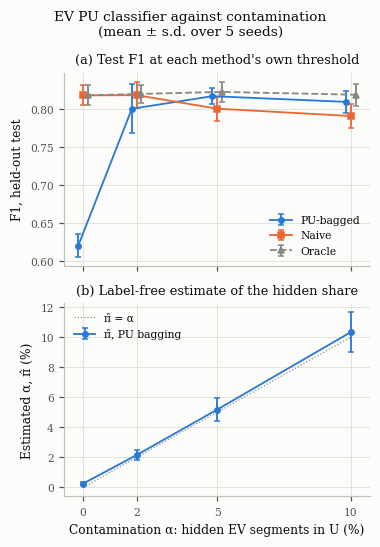

In [7]:
xs = np.array(ALPHAS) * 100
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.0), sharex=True)

    ax = axes[0]
    for k, mth in enumerate(METHODS):
        sub = results[results.method == mth].groupby("alpha")["F1"]
        st = METHOD_STYLE[mth]
        ax.errorbar(xs + (k - 1) * 0.18, sub.mean().values, yerr=sub.std().values,
                    color=st["color"], marker=st["marker"], ls=st["ls"], lw=1.2, ms=3.5,
                    capsize=2, label=mth.replace(" XGBoost", ""))
    ax.set_ylabel("F1, held-out test")
    ax.set_title("(a) Test F1 at each method's own threshold")
    ax.legend(loc="lower right", frameon=False)

    ax = axes[1]
    sub = results[results.method == "PU-bagged XGBoost"].groupby("alpha")["pi_hat"]
    ax.plot([0, 10], [0, 10], color=INK_MUTED, lw=0.8, ls=":", label="π̂ = α")
    ax.errorbar(xs, sub.mean().values * 100, yerr=sub.std().values * 100,
                color=CAT["blue"], marker="o", lw=1.2, ms=3.5, capsize=2, label="π̂, PU bagging")
    ax.set_xlabel("Contamination α: hidden EV segments in U (%)")
    ax.set_ylabel("Estimated α, π̂ (%)")
    ax.set_title("(b) Label-free estimate of the hidden share")
    ax.set_xticks(xs)
    ax.legend(loc="upper left", frameon=False)

    fig.suptitle("EV PU classifier against contamination\n(mean ± s.d. over 5 seeds)", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EV_PU1_f1_and_pi_hat_vs_alpha")
    plt.show()

## 7. Table EV_PU_T3 - PU bagging at α = 5% on the held-out test

The detailed results use **all five PU-bagged runs at α = 5%**, the contamination closest to the
true prevalence. Each run scores the 3,940 test segments with its own
ensemble (5 folds × 25 bags of XGBoost boosters, mean margin) and flags them at its own PU-F1
threshold.

The table gives the mean ± standard deviation over the five seeds, at the test prevalence (10%)
and with precision and F1 restated at 5% and 2%. **F1 restated at 5% is the headline EV result**,
as α = 5% and 5% prevalence are the closest to GB levels. Recall is also
given for each regime and charge-power class, and the false-positive rate for each heating type of
the households without an EV (from the LCL survey). The ± values are seed spread, not confidence
intervals.

In [8]:
ev_mask = test["label"].to_numpy() == 1
per_seed = []
for seed, pu in main_runs.items():
    test[f"score_{seed}"] = pu["test"]
    test[f"flag_{seed}"] = (pu["test"] >= pu["threshold"]).astype(int)
    f = test[f"flag_{seed}"].to_numpy()
    r = pc.score_row(y_test, pu["test"], pu["threshold"])
    row = {"ROC-AUC": r["ROC_AUC"], "PR-AUC": r["PR_AUC"], "Recall": r["recall"],
           "False-positive rate": r["FPR"], "Precision at 10%": r["precision"], "F1 at 10%": r["F1"]}
    for p in RESTATE_AT:
        row[f"Precision restated at {p:.0%}"], row[f"F1 restated at {p:.0%}"] = \
            pc.restate(r["recall"], r["FPR"], p)
    for rg in REGIMES:
        row[f"Recall, {rg}"] = f[ev_mask & (test.regime == rg).to_numpy()].mean()
    for c in POWER_CLASSES:
        row[f"Recall, {c}"] = f[ev_mask & (test.power_class == c).to_numpy()].mean()
    for g in HEAT_GROUPS:
        row[f"FPR, {g}"] = f[~ev_mask & (test.heat_group == g).to_numpy()].mean()
    per_seed.append(row)
    print(f"seed {seed}: configuration {pu['params']}, threshold {pu['threshold']:.3f}, "
          f"pi_hat {pu['pi_hat']:.3f} (true {MAIN_ALPHA:.0%})")
per_seed = pd.DataFrame(per_seed, index=pd.Index(list(main_runs), name="seed"))
savetable(per_seed.round(4), "EV_PU_S_alpha5_by_seed")

ev_test = test[ev_mask]
n_of = {**{f"FPR, {g}": ((test.label == 0) & (test.heat_group == g)).sum() for g in HEAT_GROUPS},
        **{f"Recall, {rg}": (ev_test.regime == rg).sum() for rg in REGIMES},
        **{f"Recall, {c}": (ev_test.power_class == c).sum() for c in POWER_CLASSES}}
col = {"Segments (EV)": f"{len(test):,} ({int(y_test.sum())})"}
for k in per_seed.columns:
    dp = 4 if k == "False-positive rate" or k.startswith("FPR") else 3
    label = f"{k} (n={n_of[k]})" if k in n_of else k
    col[label] = f"{per_seed[k].mean():.{dp}f} ± {per_seed[k].std():.{dp}f}"
t2 = pd.DataFrame({f"PU-bagged XGBoost, α = {MAIN_ALPHA:.0%} (5 seeds)": col})
savetable(t2, "EV_PU_T3_pu_alpha5_test")
t2

seed 0: configuration {'max_depth': 5, 'u_ratio': 3}, threshold 1.637, pi_hat 0.044 (true 5%)
seed 1: configuration {'max_depth': 5, 'u_ratio': 3}, threshold 2.192, pi_hat 0.053 (true 5%)
seed 2: configuration {'max_depth': 3, 'u_ratio': 1}, threshold 2.227, pi_hat 0.055 (true 5%)
seed 3: configuration {'max_depth': 3, 'u_ratio': 3}, threshold 1.880, pi_hat 0.044 (true 5%)
seed 4: configuration {'max_depth': 5, 'u_ratio': 3}, threshold 1.142, pi_hat 0.062 (true 5%)
saved -> tables/EV_PU_S_alpha5_by_seed.csv
saved -> tables/EV_PU_T3_pu_alpha5_test.csv


,"PU-bagged XGBoost, α = 5% (5 seeds)"
Segments (EV),"3,940 (394)"
ROC-AUC,0.978 ± 0.001
PR-AUC,0.889 ± 0.010
Recall,0.797 ± 0.047
False-positive rate,0.0171 ± 0.0069
Precision at 10%,0.842 ± 0.045
F1 at 10%,0.817 ± 0.010
Precision restated at 5%,0.719 ± 0.068
F1 restated at 5%,0.753 ± 0.022
Precision restated at 2%,0.503 ± 0.083


### The exported classifiers (for notebook 09)

Notebook `09_ev_detector_on_hp` applies the five α = 5% runs, unchanged, to heat-pump households
that the EV classifier has never seen. Each run is saved in the heat-pump file format
(`pu_common.export_ensemble`): 5 folds × 25 bags of XGBoost boosters, scored by the mean margin,
with the threshold PU-F1 chose on its out-of-fold scores. The reload check scores the test segments
from each file and compares them with the run's own scores.

In [9]:
for seed, pu in main_runs.items():
    model_meta = {
        "technology": "ev", "created": date.today().isoformat(),
        "notebook": "07_ev_pu_classifier",
        "training_data": "LCL_EN_join_v2 training split (arm N hosts and donors, Electric Nation "
                         "chargers in T1 control, T1, T2 and T3)",
        "unit": f"{ef.SEGMENT_DAYS}-day segment, GMT, features from ev_features.py",
        "method": "PU-bagged XGBoost (Mordelet & Vert 2014), cross-fitted, 5 folds grouped by "
                  "charger and household",
        "params": {**pu["params"], "n_bags": pc.N_BAGS, **pc.XGB_BASE},
        "threshold_rule": "PU-F1 (label-free), add-one smoothed",
        "training_alpha": MAIN_ALPHA, "training_seed": seed,
        "l_charger_share": L_CHARGER_SHARE, "u_size": U_SIZE, "pi_hat_training": pu["pi_hat"],
    }
    path = Path(MODEL_PATH.format(seed=seed))
    pc.export_ensemble(path, pu["models"], FEATURES, pu["threshold"], model_meta)
    err = np.abs(pc.ExportedPUModel(path).decision_function(test) - pu["test"]).max()
    assert err < 1e-4, err
    print(f"seed {seed}: -> {path.name} ({path.stat().st_size / 1e6:.0f} MB), reload matches to "
          f"{err:.1e}; threshold {pu['threshold']:.3f}")

seed 0: -> ev_pu_classifier_alpha5_seed0.json (72 MB), reload matches to 3.7e-06; threshold 1.637
seed 1: -> ev_pu_classifier_alpha5_seed1.json (71 MB), reload matches to 4.1e-06; threshold 2.192
seed 2: -> ev_pu_classifier_alpha5_seed2.json (44 MB), reload matches to 3.3e-06; threshold 2.227
seed 3: -> ev_pu_classifier_alpha5_seed3.json (46 MB), reload matches to 3.2e-06; threshold 1.880
seed 4: -> ev_pu_classifier_alpha5_seed4.json (72 MB), reload matches to 3.7e-06; threshold 1.142


## 8. Figure EV_PU2 - Which features the classifier uses

Mean absolute SHAP value of each feature on the test segments. SHAP values are additive in the
margin, so an ensemble's values are the mean over its boosters. The bars are the mean over the
five α = 5% runs and the whiskers their standard deviation.

saved -> tables/EV_PU_S_shap_importance.csv
saved -> figures/EV_PU2_shap_top10.png


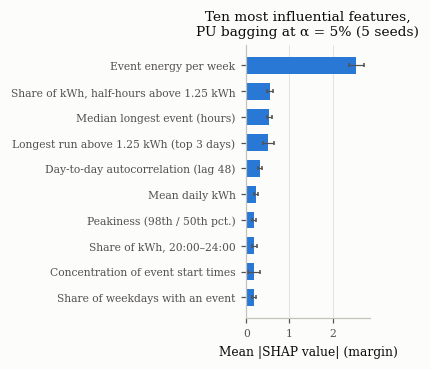

In [10]:
FEATURE_LABELS = {
    "avg_daily_kwh": "Mean daily kWh",
    "cv_daily_kwh": "Coefficient of variation of daily kWh",
    "sigma2_delta": "Half-hour step variance",
    "rho_48": "Day-to-day autocorrelation (lag 48)",
    "s_peak": "Peakiness (98th / 50th pct.)",
    "night_share": "Share of kWh, 00:00–07:00",
    "am_peak_share": "Share of kWh, 06:00–09:00",
    "pm_peak_share": "Share of kWh, 16:00–20:00",
    "late_evening_share": "Share of kWh, 20:00–24:00",
    "weekend_ratio": "Weekend / weekday daily kWh",
    "q99_hh": "99th pct. half-hourly kWh",
    "high_energy_share": "Share of kWh, half-hours above 1.25 kWh",
    "longest_run_1p25": "Longest run above 1.25 kWh (top 3 days)",
    "max_step_up": "Largest half-hour rise (top 3 days)",
    "plateau_flatness": "High-power plateau flatness (top 3 days)",
    "event_rate_weekday": "Share of weekdays with an event",
    "event_rate_weekend": "Share of weekend days with an event",
    "event_kwh_per_week": "Event energy per week",
    "event_hours_median": "Median longest event (hours)",
    "onset_concentration": "Concentration of event start times",
}

Xt = test[FEATURES].to_numpy(float)
imp_seed = {}
for seed, pu in main_runs.items():
    boosters = [m.get_booster() for fm in pu["models"] for m in fm.models]
    sv = np.zeros(Xt.shape)
    for b in boosters:
        sv += shap.TreeExplainer(b).shap_values(Xt) / len(boosters)
    imp_seed[seed] = np.abs(sv).mean(axis=0)
imp_seed = pd.DataFrame(imp_seed, index=FEATURES)
imp = pd.DataFrame({"mean_abs_shap": imp_seed.mean(axis=1), "sd_over_seeds": imp_seed.std(axis=1)})
imp = imp.sort_values("mean_abs_shap", ascending=False)
savetable(imp, "EV_PU_S_shap_importance")

top = imp.head(10)[::-1]
with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.4))
    ax.barh([FEATURE_LABELS[f] for f in top.index], top.mean_abs_shap, xerr=top.sd_over_seeds,
            color=CAT["blue"], height=0.65, error_kw=dict(ecolor=INK_SECONDARY, lw=0.8, capsize=1.5))
    ax.set_xlabel("Mean |SHAP value| (margin)")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Ten most influential features,\nPU bagging at α = {MAIN_ALPHA:.0%} (5 seeds)", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EV_PU2_shap_top10")
    plt.show()

### Figure EV_PU3 - Pairwise plot of the five most influential features

The five features with the largest mean |SHAP| on the same test segments, by EV label, so the
pattern behind the SHAP ranking can be seen directly.
- **Below the diagonal:** each segment as a point. Segments without an EV are drawn first, so EV
  segments sit on top.
- **On the diagonal:** the distribution of each feature within each class, as densities, so the two
  classes compare despite the 10% prevalence. The y-axis is scaled to the EV curve, so the no-EV
  spike at zero runs off the top.
- **Above the diagonal:** Spearman's rank correlation within each class, over segments where both
  features are defined.

Segments with no suspected event have no event duration; the model treats that as missing, and
here they are plotted at 0 hours so they stay visible. Axes stop at the 99.9th percentile, which
leaves out a few extreme points.

saved -> figures/EV_PU3_pairplot_top5.png


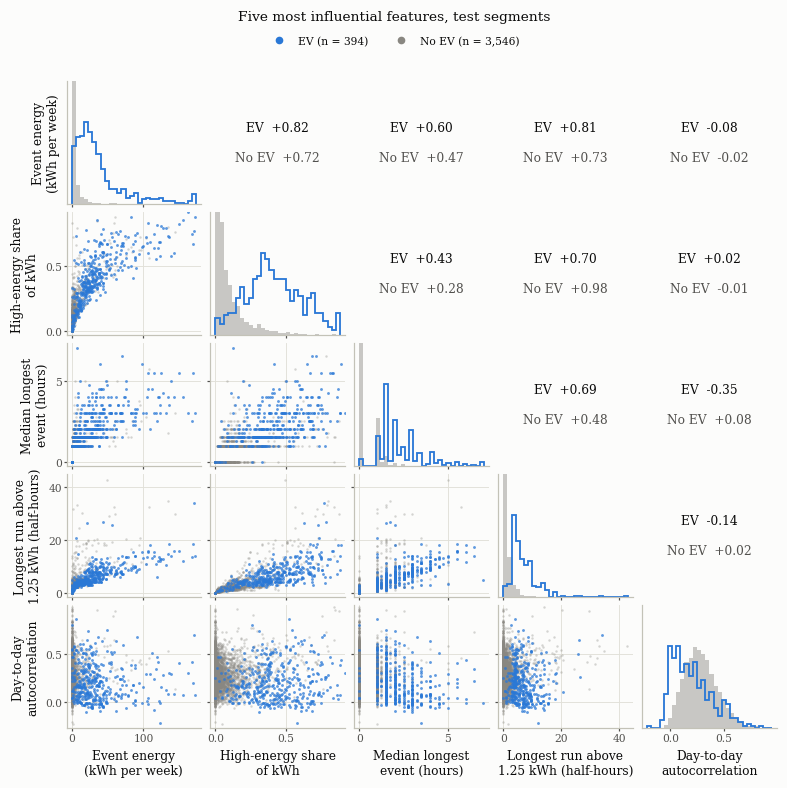

In [11]:
PAIR_LABELS = {"event_kwh_per_week": "Event energy\n(kWh per week)",
               "high_energy_share": "High-energy share\nof kWh",
               "event_hours_median": "Median longest\nevent (hours)",
               "longest_run_1p25": "Longest run above\n1.25 kWh (half-hours)",
               "rho_48": "Day-to-day\nautocorrelation"}
FULL_WIDTH = 7.2
top5 = list(imp.index[:5])
P = test[top5].fillna({"event_hours_median": 0})
is_ev = test["label"].to_numpy() == 1
limits = {f: (P[f].min(), P[f].quantile(0.999)) for f in top5}
pad = {f: 0.04 * (hi - lo) for f, (lo, hi) in limits.items()}
lab = lambda f: PAIR_LABELS.get(f, FEATURE_LABELS[f])
n = len(top5)

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(n, n, figsize=(FULL_WIDTH, FULL_WIDTH))
    for i, fy in enumerate(top5):
        for j, fx in enumerate(top5):
            ax = axes[i, j]
            if i < j:
                ax.axis("off")
                rho_ev = test.loc[is_ev, [fx, fy]].corr("spearman").iloc[0, 1]
                rho_no = test.loc[~is_ev, [fx, fy]].corr("spearman").iloc[0, 1]
                ax.text(0.5, 0.62, f"EV  {rho_ev:+.2f}", ha="center", va="center",
                        transform=ax.transAxes)
                ax.text(0.5, 0.38, f"No EV  {rho_no:+.2f}", ha="center", va="center",
                        transform=ax.transAxes, color=INK_SECONDARY)
                continue
            if i == j:
                bins = np.linspace(*limits[fx], 31)
                x = P[fx].clip(*limits[fx])
                ax.hist(x[~is_ev], bins=bins, density=True, histtype="stepfilled",
                        color=INK_MUTED, alpha=0.45, lw=0)
                d = ax.hist(x[is_ev], bins=bins, density=True, histtype="step",
                            color=CAT["blue"], lw=1.2)[0]
                ax.set_ylim(0, d.max() * 1.5)
                ax.set_yticks([])
                ax.grid(False)
            else:
                ax.scatter(P.loc[~is_ev, fx], P.loc[~is_ev, fy], s=2.5, color=INK_MUTED,
                           alpha=0.35, lw=0)
                ax.scatter(P.loc[is_ev, fx], P.loc[is_ev, fy], s=3.5, color=CAT["blue"],
                           alpha=0.75, lw=0)
                ax.set_ylim(limits[fy][0] - pad[fy], limits[fy][1] + pad[fy])
            ax.set_xlim(limits[fx][0] - pad[fx], limits[fx][1] + pad[fx])
            ax.tick_params(length=2, pad=1)
            ax.locator_params(nbins=3)
            if i < n - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(lab(fx))
            if j == 0:
                ax.set_ylabel(lab(fy))
            elif i != j:
                ax.set_yticklabels([])
    handles = [plt.Line2D([], [], marker="o", ls="none", ms=4, color=CAT["blue"],
                          label=f"EV (n = {is_ev.sum():,})"),
               plt.Line2D([], [], marker="o", ls="none", ms=4, color=INK_MUTED,
                          label=f"No EV (n = {(~is_ev).sum():,})")]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 0.965))
    fig.suptitle("Five most influential features, test segments", fontsize=9, y=0.985)
    fig.tight_layout(rect=(0, 0, 1, 0.945), h_pad=0.4, w_pad=0.4)
    savefig(fig, "EV_PU3_pairplot_top5")
    plt.show()

## 9. Table EV_PU_T4 - Comparison with a rule-based charging detector

The rule is the suspected-charging screen of notebook 01 (section 14), applied unchanged to the
same test segments, with no training and no tuning:
- an **event** is a run of 4 to 12 consecutive half-hours, each above 3.5 kWh (7 kW);
- a segment is **flagged** when it has 0.5 to 4 events per week (events ÷ complete days × 7).

It is compared with the three methods at α = 5% (mean ± s.d. over 5 seeds). Precision and F1 are
given at the test prevalence (10%) and **restated at 5%**. Recall by regime and charge-power class
is given for the rule and for PU bagging.

In [12]:
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
con.register("test_ids", test[["segment_id"]])
ev_counts = con.execute(f"""
    WITH t AS (
        SELECT h.segment_id, (h.date - DATE '2011-01-01') * 48 + h.hh_index AS k
        FROM '{V2}/ev_dataset_hh30.parquet' h JOIN test_ids USING (segment_id)
        WHERE h.kwh > {RULE_KWH}),
    r AS (SELECT segment_id, k - row_number() OVER (PARTITION BY segment_id ORDER BY k) AS g FROM t),
    runs AS (SELECT segment_id, count(*) AS n FROM r GROUP BY segment_id, g)
    SELECT segment_id, count(*) FILTER (WHERE n BETWEEN {RULE_MIN_RUN} AND {RULE_MAX_RUN}) AS events
    FROM runs GROUP BY 1
""").df()
con.close()
test = test.merge(ev_counts, on="segment_id", how="left").fillna({"events": 0})
test["rule_rate"] = test.events / (test.n_complete_days / 7)
test["rule_flag"] = test.rule_rate.between(RULE_RATE_MIN, RULE_RATE_MAX).astype(int)
ev_mask = test["label"].to_numpy() == 1


def flag_metrics(f):
    """Recall, FPR, precision and F1 (at 10% and restated at 5%) of one set of test flags, with
    recall by charge-power class and regime."""
    r, fpr = f[ev_mask].mean(), f[~ev_mask].mean()
    tp, fp = f[ev_mask].sum(), f[~ev_mask].sum()
    p = tp / (tp + fp) if tp + fp else 0.0
    p5, f5 = pc.restate(r, fpr, RULE_PREVALENCE)
    out = {"Recall": r, "False-positive rate": fpr, "Precision at 10%": p,
           "F1 at 10%": 2 * p * r / (p + r) if p + r else 0.0,
           "Precision restated at 5%": p5, "F1 restated at 5%": f5}
    for c in POWER_CLASSES:
        out[f"Recall, {c}"] = f[ev_mask & (test.power_class == c).to_numpy()].mean()
    for rg in REGIMES:
        out[f"Recall, {rg}"] = f[ev_mask & (test.regime == rg).to_numpy()].mean()
    return out


def fmt(d, sd=None):
    return {k: (f"{v:.4f}" if k == "False-positive rate" else f"{v:.3f}")
            + ("" if sd is None else (f" ± {sd[k]:.4f}" if k == "False-positive rate" else f" ± {sd[k]:.3f}"))
            for k, v in d.items()}


def from_rows(d):
    d = d.copy()
    d["p5"] = [pc.restate(r, f, RULE_PREVALENCE)[0] for r, f in zip(d.recall, d.FPR)]
    d["f5"] = [pc.restate(r, f, RULE_PREVALENCE)[1] for r, f in zip(d.recall, d.FPR)]
    cols = {"recall": "Recall", "FPR": "False-positive rate", "precision": "Precision at 10%",
            "F1": "F1 at 10%", "p5": "Precision restated at 5%", "f5": "F1 restated at 5%"}
    d = d[list(cols)].rename(columns=cols)
    return fmt(d.mean(), d.std())


pu_flags = pd.DataFrame([flag_metrics(test[f"flag_{s}"].to_numpy()) for s in main_runs])
a5 = results[results.alpha == MAIN_ALPHA]
t3 = {"Rule-based detector": fmt(flag_metrics(test["rule_flag"].to_numpy())),
      f"PU-bagged, α = {MAIN_ALPHA:.0%} (5 seeds)": fmt(pu_flags.mean(), pu_flags.std()),
      **{f"{m.replace(' XGBoost', '')}, α = {MAIN_ALPHA:.0%} (5 seeds)": from_rows(a5[a5.method == m])
         for m in METHODS[1:]}}
t3 = pd.DataFrame(t3).fillna("–")
t3.index.name = "EV_PU_T4  Rule-based detector against the PU classifier, test segments"
savetable(t3, "EV_PU_T4_rule_vs_pu")
print(f"rule: {int(test.rule_flag.sum())} segments flagged; "
      f"{(test[ev_mask].events > 0).mean():.1%} of EV segments have at least one event")
t3

saved -> tables/EV_PU_T4_rule_vs_pu.csv
rule: 107 segments flagged; 32.5% of EV segments have at least one event


,Rule-based detector,"PU-bagged, α = 5% (5 seeds)","Naive, α = 5% (5 seeds)","Oracle, α = 5% (5 seeds)"
"EV_PU_T4 Rule-based detector against the PU classifier, test segments",,,,
Recall,0.251,0.797 ± 0.047,0.883 ± 0.006,0.862 ± 0.009
False-positive rate,0.0023,0.0171 ± 0.0069,0.0359 ± 0.0053,0.0259 ± 0.0049
Precision at 10%,0.925,0.842 ± 0.045,0.733 ± 0.029,0.788 ± 0.031
F1 at 10%,0.395,0.817 ± 0.010,0.801 ± 0.016,0.823 ± 0.014
Precision restated at 5%,0.854,0.719 ± 0.068,0.566 ± 0.038,0.639 ± 0.043
F1 restated at 5%,0.388,0.753 ± 0.022,0.689 ± 0.026,0.733 ± 0.025
"Recall, 3.5 kW class",0.000,0.705 ± 0.058,–,–
"Recall, 7 kW class",0.503,0.890 ± 0.040,–,–
"Recall, T1 control",0.375,0.800 ± 0.068,–,–


## 10. Figures EV_PU4 and EV_PU4b - ROC and precision–recall curves, with the rule as a point

The curves of the five α = 5% runs on the test segments, with their mean operating point (each
run's own PU-F1 threshold; whiskers ± 1 s.d. over seeds) and the rule-based detector's single
operating point. The two figures share panel (a) and differ in the prevalence of panel (b).
- **(a) ROC.** True-positive rate against false-positive rate. Neither depends on prevalence, so
  the test set gives them directly.
- **(b) Precision–recall.** Precision does depend on prevalence. In **EV_PU4** each curve is
  restated at 5%, the headline setting (α = 5%, 5% prevalence) and the prevalence of the rule
  comparison, from each threshold's recall and false-positive rate. In **EV_PU4b** it is at the
  test set's own prevalence (10%), as observed. The dotted line is a classifier that flags at
  random.

saved -> figures/EV_PU4_roc_pr_rule.png


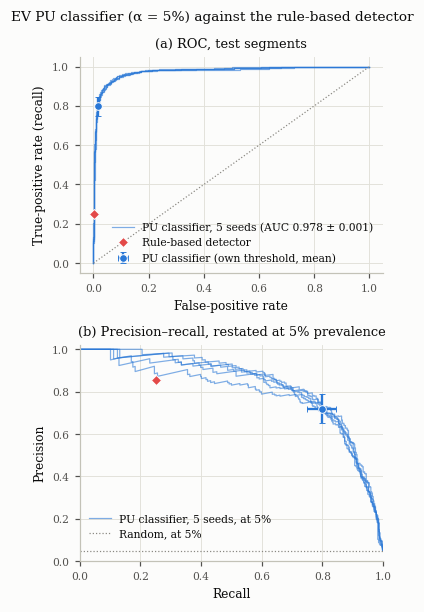

saved -> figures/EV_PU4b_roc_pr_rule_test_prevalence.png


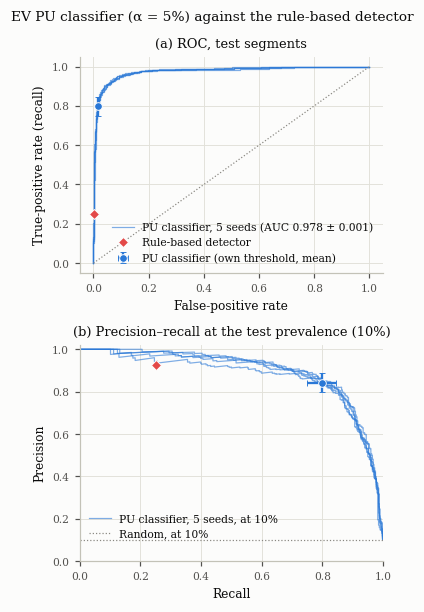

PU classifier: recall 0.797, FPR 0.0171, precision at 5% 0.711, at 10% 0.838
Rule-based detector: recall 0.251, FPR 0.0023, precision at 5% 0.854, at 10% 0.925


In [13]:
pi = RULE_PREVALENCE
TEST_PREVALENCE = y_test.mean()
pu_pts = pd.DataFrame([{"fpr": test.loc[~ev_mask, f"flag_{s}"].mean(),
                        "recall": test.loc[ev_mask, f"flag_{s}"].mean()} for s in main_runs])
rf = test["rule_flag"].to_numpy()
rule_pt = (rf[~ev_mask].mean(), rf[ev_mask].mean())
auc_mean, auc_sd = per_seed["ROC-AUC"].mean(), per_seed["ROC-AUC"].std()


def roc_pr_figure(prev, b_title, name):
    prec = np.array([pc.restate(r, f, prev)[0] for r, f in zip(pu_pts.recall, pu_pts.fpr)])
    rule_prec = pc.restate(rule_pt[1], rule_pt[0], prev)[0]
    with plt.rc_context(COLUMN_RC):
        fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.6))
        for k, seed in enumerate(main_runs):
            fpr_c, tpr_c, _ = roc_curve(y_test, test[f"score_{seed}"])
            with np.errstate(invalid="ignore", divide="ignore"):
                prec_pi = np.where(tpr_c > 0, tpr_c * prev / (tpr_c * prev + fpr_c * (1 - prev)), 1.0)
            lab = f"PU classifier, 5 seeds (AUC {auc_mean:.3f} ± {auc_sd:.3f})" if k == 0 else None
            axes[0].plot(fpr_c, tpr_c, color=CAT["blue"], lw=0.8, alpha=0.6, label=lab)
            axes[1].plot(tpr_c, prec_pi, color=CAT["blue"], lw=0.8, alpha=0.6,
                         label=f"PU classifier, 5 seeds, at {prev:.0%}" if k == 0 else None)

        ax = axes[0]
        ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=0.8, ls=":")
        ax.errorbar(pu_pts.fpr.mean(), pu_pts.recall.mean(), xerr=pu_pts.fpr.std(), yerr=pu_pts.recall.std(),
                    marker="o", color=CAT["blue"], ms=5, ls="none", mec="white", mew=0.6, capsize=2,
                    label="PU classifier (own threshold, mean)")
        ax.plot(*rule_pt, marker="D", color=RULE_COLOR, ms=5, ls="none", mec="white", mew=0.6,
                label="Rule-based detector")
        ax.set_xlabel("False-positive rate")
        ax.set_ylabel("True-positive rate (recall)")
        ax.set_title("(a) ROC, test segments")
        ax.legend(loc="lower right", frameon=False)

        ax = axes[1]
        ax.axhline(prev, color=INK_MUTED, lw=0.8, ls=":", label=f"Random, at {prev:.0%}")
        ax.errorbar(pu_pts.recall.mean(), prec.mean(), xerr=pu_pts.recall.std(), yerr=prec.std(ddof=1),
                    marker="o", color=CAT["blue"], ms=5, ls="none", mec="white", mew=0.6, capsize=2)
        ax.plot(rule_pt[1], rule_prec, marker="D", color=RULE_COLOR, ms=5, ls="none", mec="white", mew=0.6)
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.set_ylim(0, 1.02)
        ax.set_xlim(0, 1.0)
        ax.set_title(b_title)
        ax.legend(loc="lower left", bbox_to_anchor=(0, 0.06), frameon=False)
        fig.suptitle(f"EV PU classifier (α = {MAIN_ALPHA:.0%}) against the rule-based detector", fontsize=9)
        fig.tight_layout()
        savefig(fig, name)
        plt.show()


roc_pr_figure(RULE_PREVALENCE, f"(b) Precision–recall, restated at {RULE_PREVALENCE:.0%} prevalence",
              "EV_PU4_roc_pr_rule")
roc_pr_figure(TEST_PREVALENCE, f"(b) Precision–recall at the test prevalence ({TEST_PREVALENCE:.0%})",
              "EV_PU4b_roc_pr_rule_test_prevalence")

pts = {"PU classifier": (pu_pts.fpr.mean(), pu_pts.recall.mean()), "Rule-based detector": rule_pt}
for name, (fp, r) in pts.items():
    print(f"{name}: recall {r:.3f}, FPR {fp:.4f}, precision at {pi:.0%} {pc.restate(r, fp, pi)[0]:.3f}, "
          f"at {TEST_PREVALENCE:.0%} {pc.restate(r, fp, TEST_PREVALENCE)[0]:.3f}")

## 11. Figure EV_PU5 - Confusion matrices per 1,000 households at 5% prevalence

A confusion matrix's counts depend on prevalence, so the test set's counts (10% EV) would not
describe a deployment. Each matrix instead shows the **expected counts in 1,000 households of
which 5% (50) charge an EV**, from each detector's test recall and false-positive rate:
true positives = 50 × recall, false positives = 950 × false-positive rate. The PU classifier's
recall and false-positive rate are the means over the five α = 5% runs.

saved -> figures/EV_PU5_confusion_per_1000.png


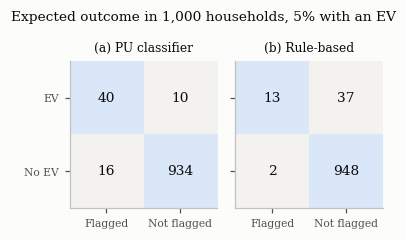

In [14]:
N_HH = 1000
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(1, 2, figsize=(COL_WIDTH, 2.1))
    for ax, (name, (fp, r)), tag in zip(axes, pts.items(), "ab"):
        npos, nneg = N_HH * pi, N_HH * (1 - pi)
        cm = np.array([[npos * r, npos * (1 - r)], [nneg * fp, nneg * (1 - fp)]])
        ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f3f2ee", "#d9e7f8"]),
                  vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=9,
                        color=INK_PRIMARY)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Flagged", "Not flagged"])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["EV", "No EV"] if tag == "a" else ["", ""])
        ax.grid(False)
        short = "PU classifier" if tag == "a" else "Rule-based"
        ax.set_title(f"({tag}) {short}", fontsize=8)
    fig.suptitle(f"Expected outcome in {N_HH:,} households, {pi:.0%} with an EV", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EV_PU5_confusion_per_1000")
    plt.show()

## 12. Notes and limitations

- Contamination is simulated. The London pool has almost no EVs, so the hidden positives are
  constructed segments.
- PU learning assumes the labelled EVs are a random sample of all EVs. That holds here by
  construction, but known EV households may differ from the rest in practice.
- Test prevalence is 10%, so precision and F1 are also restated at 5% and 2%.
- The model detects home charging in a 21-day window, not EV ownership.
- The rule-based detector can't see 3.5 kW chargers, because its threshold needs about 7 kW of
  load (Table EV_PU_T4).
- The ± values are the spread over five seeds, not confidence intervals. Segments from one charger
  are correlated, which the grouped folds handle in training.
- T1 control is small (8 test segments), so its recall in Table EV_PU_T3 is only indicative.